# Highway Networks na CIFAR-10

Notatnik przygotowany w oparciu o pracę: Srivastava, Greff, Schmidhuber — *Highway Networks* (arXiv:1505.00387v2, 2015).

Notatnik zawiera:
1. wyjaśnienie koncepcji i zasady działania sieci typu Highway,
2. implementację konwolucyjnej sieci Highway Network,
3. trening i ewaluację na zbiorze CIFAR-10,
4. wykresy krzywych uczenia.

## 1. Zasada działania sieci Highway

### Problem uczenia głębokich sieci
Zwiększanie liczby warstw (głębokości) sieci neuronowej pozwala jej modelować znacznie bardziej złożone zależności. W praktyce jednak w klasycznych, jednokierunkowych sieciach po przekroczeniu pewnej liczby warstw proces uczenia załamuje się: podczas propagacji wstecznej sygnał błędu (gradient) musi przejść przez długi łańcuch mnożeń i po drodze zanika (spada niemal do zera) lub staje się niestabilny. W rezultacie początkowe warstwy głębokiej sieci przestają się uczyć nawet wtedy, gdy stosujemy staranne metody doboru wag początkowych (takie jak inicjalizacja Glorota lub He).

### Rozwiązanie: warstwa z bramkowaniem przepływu informacji
Autorzy pracy proponują mechanizm bramkowania wzorowany na pamięci długotrwałej z sieci rekurencyjnych (LSTM). Zamiast zmuszać każdą warstwę do całkowitego przekształcania sygnału wejściowego $x$, warstwa otrzymuje dwa regulowane tory — tor przekształcenia oraz tor bezpośredniego przeniesienia:

$$
y = H(x, W_H) \cdot T(x, W_T) + x \cdot \bigl(1 - T(x, W_T)\bigr)
$$

- $H(x, W_H)$ — **nieliniowe przekształcenie wejścia** (w sieci obrazowej: splot z wagami $W_H$, normalizacja oraz funkcja aktywacji),
- $T(x, W_T) = \sigma(W_T x + b_T)$ — **bramka przekształcenia**, która dzięki funkcji sigmoidalnej $\sigma$ zwraca wartości z przedziału $(0, 1)$ i decyduje, jaki ułamek nowego sygnału $H(x)$ wpuścić na wyjście,
- $C(x, W_T) = 1 - T(x, W_T)$ — **bramka przeniesienia**, która określa, jaka część niezmienionego sygnału wejściowego $x$ ma przejść przez warstwę bezpośrednio dalej.

Interpretacja skrajnych stanów bramki:
- gdy $T(x) \approx 0$, wówczas $y \approx x$ — warstwa działa jak „autostrada informacyjna” i przepuszcza sygnał (oraz pochodne w trakcie uczenia) bez żadnych strat,
- gdy $T(x) \approx 1$, wówczas $y \approx H(x)$ — warstwa zachowuje się jak zwykła warstwa klasycznej sieci neuronowej.

### Kluczowe szczegóły implementacyjne
1. **Zgodność wymiarów i zmiana liczby kanałów poza warstwami Highway:**
   Aby można było pomnożyć po współrzędnych i dodać do siebie tensory w równaniu $y = H(x) \cdot T(x) + x \cdot (1 - T(x))$, wejście $x$, przekształcenie $H(x)$ oraz bramka $T(x)$ muszą mieć identyczne wymiary (tę samą wysokość, szerokość oraz liczbę kanałów). Z tego powodu w miejscach, gdzie architektura sieci wymaga zwiększenia liczby kanałów (np. z $3$ na $32$ lub z $32$ na $64$), stosuje się pojedynczą **zwykłą warstwę konwolucyjną**, a dopiero za nią układa się kolejne warstwy Highway pracujące na stałej liczbie kanałów.
2. **Ujemna wartość początkowa przesunięcia (biasu) bramki $b_T$:**
   Na samym początku treningu wagi $W_T$ są losowane blisko zera, więc o otwarciu bramki decyduje jej wyraz wolny $b_T$. Autorzy inicjują wektor $b_T$ liczbą ujemną (np. $-2.0$). Ponieważ dla argumentu $-2.0$ funkcja sigmoidalna przyjmuje wartość $\sigma(-2.0) \approx 0.12$, na starcie treningu każda warstwa w około $88\%$ przepuszcza nienaruszony sygnał wejściowy ($1 - T \approx 0.88$). Dzięki temu od pierwszej epoki gradienty swobodnie docierają do najgłębszych warstw, a w miarę postępu nauki sieć sama otwiera tylko te bramki, które są jej potrzebne.
3. **Konstrukcja konwolucyjna z zachowaniem rozmiaru mapy cech:**
   W przypadku przetwarzania obrazów zarówno transformacja $H$, jak i bramka $T$ są realizowane jako osobne operacje splotu (współdzielenie wag w przestrzeni obrazu). Aby splot filtrem o wymiarze np. $3 \times 3$ nie zmniejszał wysokości i szerokości obrazu na brzegach, przed wykonaniem splotu obraz uzupełnia się ramką złożoną z zer o grubości jednego piksela. Gwarantuje to, że mapa cech po przejściu przez $H(x)$ i $T(x)$ ma dokładnie taką samą wysokość i szerokość jak wejście $x$.
4. **Bezpośrednie uczenie prostym algorytmem spadku wzdłuż gradientu:**
   Dzięki drożnym ścieżkom przenoszenia sygnału bardzo głębokie sieci Highway nie wymagają wstępnego uczenia warstwa po warstwie ani dodatkowych sieci pomocniczych („nauczycieli”) — można je wytrenować od zera klasyczną metodą spadku wzdłuż gradientu z pędem.

## 2. Setup i parametry eksperymentu

W poniższej komórce definiujemy wszystkie hiperparametry architektury i procesu uczenia oraz sprawdzamy dostępność karty graficznej (`cuda`):

- **`RETRAIN = False`** — gdy `False`, notebook wczytuje zapisaną historię i najlepszy checkpoint z `./runs` (pozwala szybko odtworzyć wykresy i ewaluację). Ustawienie `True` uruchamia pełny trening od zera.
- **`STAGE_WIDTHS = (32, 64, 96)`** — sieć konwolucyjna dla obrazów $32 \times 32$ składa się z **3 etapów (stages)** przedzielonych dwukrotnym zmniejszaniem rozdzielczości (`MaxPool2d(2)`): $32 \times 32 \to 16 \times 16 \to 8 \times 8$. Wraz ze spadkiem rozdzielczości przestrzennej zwiększamy liczbę kanałów (filtrów) wielokrotnościami 32, aby kolejne etapy mogły reprezentować coraz bardziej złożone cechy obrazu.
- **`BLOCKS_PER_STAGE = (4, 4, 4)`** — w każdym z 3 etapów układamy po 4 warstwy `HighwayConv2d` jedna za drugą (łącznie daje to 3 warstwy `PlainConv2d` + 12 warstw `HighwayConv2d` + 1 warstwę klasyfikującą `Linear` = **16 warstw z wagami**, ok. $1.11\text{ mln}$ parametrów).
- **`TRANSFORM_BIAS = -2.0`** — początkowa wartość wektora biasu $b_T$ dla bramki transformacji $T(x) = \sigma(W_T x + b_T)$. Inicjalizacja ujemna sprawia, że na starcie treningu (gdy wagi $W_T \approx 0$) bramka ma wartość $T \approx \sigma(-2.0) \approx 0.12$, a bramka przeniesienia $C = 1 - T \approx 0.88$. Dzięki temu każda warstwa początkowo w ~88% przepuszcza niezmieniony sygnał wejściowy $x$, co zapobiega zanikaniu gradientów i pozwala uczyć głęboką sieć od pierwszej epoki.
- **`EPOCHS = 100`, `BATCH_SIZE = 128`, `LR = 0.05`** — zbiór treningowy dzielimy na paczki po 128 obrazów; współczynnik uczenia `LR = 0.05` został dobrany empirycznie (wyższe `LR = 0.1` prowadziło do niestabilności gradientów i `NaN`).

In [1]:
# === konfiguracja eksperymentu ===
RETRAIN = True                 # True = trenuj od zera; False = wczytaj ostatni zapisany przebieg z ./runs
STAGE_WIDTHS = (32, 64, 96)    # liczba kanalow w kolejnych etapach sieci
BLOCKS_PER_STAGE = (4, 4, 4)   # liczba warstw HighwayConv2d w kazdym etapie
TRANSFORM_BIAS = -2.0          # ujemny bias poczatkowy bramki T
EPOCHS = 100
BATCH_SIZE = 128
LR = 0.05
SEED = 42

import sys, subprocess
pkgs = ["torch", "torchvision", "tqdm", "matplotlib", "numpy"]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device = {DEVICE}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

PyTorch 2.6.0+cu124 | device = cuda
NVIDIA GeForce RTX 4080


## 3. Implementacja Highway Network

Implementacja opiera się na trzech klasach dziedziczących po `nn.Module`:

1. **`HighwayConv2d` — konwolucyjna warstwa Highway:**
   Realizuje wzór: $y = H(x) \cdot T(x) + x \cdot (1 - T(x))$.
   - **Zachowanie wymiarów (`padding = kernel_size // 2`):** Zwykły splot filtrem $3 \times 3$ bez obramowania zmniejszyłby wysokość i szerokość mapy cech o 2 piksele (np. z $32 \times 32$ do $30 \times 30$), co uniemożliwiłoby dodanie $H(x)$ do oryginalnego wejścia $x$. Dodanie ramki z zer o grubości 1 piksela (`padding = 1`) gwarantuje, że tensory $x$, $H(x)$ oraz $T(x)$ mają identyczny rozmiar przestrzenny i tę samą liczbę kanałów.
   - **Stabilizacja sygnału (`self.H_bn = nn.BatchNorm2d(channels)`):** W głębokiej sieci wielokrotne mnożenie sygnału przez wagi kolejnych warstw powoduje rozrastanie się wartości aktywacji i ryzyko wybuchu gradientów (`NaN`). Warstwa `BatchNorm2d` normalizuje wyjście konwolucji `self.H(x)` na każdej paczce danych do stabilnego zakresu wokół zera, zanim sygnał trafi do funkcji aktywacji. Ponieważ `BatchNorm2d` sama odejmuje średnią i posiada własny parametr przesunięcia, w poprzedzającej ją warstwie `self.H` ustawiamy `bias=False`.
   - **Funkcje aktywacji (`F.relu` oraz `torch.sigmoid`) i inicjalizacja wag:** Przekształcenie obrazu $H(x)$ wykorzystuje nieliniową funkcję `ReLU` ($\max(0, z)$), która zeruje wartości ujemne, wprowadza nieliniowość między warstwami i nie tłumi gradientów dla wartości dodatnich (dlatego wagi `self.H.weight` inicjujemy metodą He / Kaiminga). Natomiast bramka $T(x)$ używa funkcji `Sigmoid` ($\sigma(z) \in (0, 1)$), która działa jak płynny zawór określający w każdym punkcie mapy cech, jaką część sygnału przetransformować, a jaką przepuścić bez zmian (wagi `self.T.weight` inicjujemy metodą Xaviera, a `self.T.bias` ujemną wartością `transform_bias`).

2. **`PlainConv2d` — zwykła warstwa zmieniająca wymiar:**
   Ponieważ w warstwie Highway liczba kanałów wejścia $x$ i wyjścia $y$ musi być taka sama, na początku każdego z 3 etapów sieci używamy zwykłej warstwy konwolucyjnej (`Conv2d + BatchNorm2d + ReLU`), aby zwiększyć liczbę kanałów ($3 \to 32$, $32 \to 64$, $64 \to 96$).

3. **`HighwayCIFAR10` — pełna architektura sieci:**
   Łączy 3 etapy (`PlainConv2d` + 4 bloki `HighwayConv2d`, rozdzielone warstwami `MaxPool2d(2)`) w jeden łańcuch `nn.Sequential`. Na końcu `AdaptiveAvgPool2d(1)` uśrednia każdą z 96 map cech o wymiarze $8 \times 8$ do pojedynczej liczby (dając tensor o kształcie `(batch, 96, 1, 1)`), `torch.flatten(x, 1)` spłaszcza go do tabeli 2D `(batch, 96)`, a warstwa liniowa `nn.Linear(96, 10)` wylicza 10 logitów odpowiadających klasom CIFAR-10.

In [2]:
class HighwayConv2d(nn.Module):
    """Konwolucyjna warstwa Highway: y = H(x) * T(x) + x * (1 - T(x))."""

    def __init__(self, channels: int, transform_bias: float, kernel_size: int = 3):
        super().__init__()
        padding = kernel_size // 2
        self.H = nn.Conv2d(channels, channels, kernel_size, padding=padding, bias=False)
        self.H_bn = nn.BatchNorm2d(channels)
        self.T = nn.Conv2d(channels, channels, kernel_size, padding=padding, bias=True)

        nn.init.kaiming_normal_(self.H.weight, mode="fan_out", nonlinearity="relu")
        nn.init.xavier_normal_(self.T.weight)
        nn.init.constant_(self.T.bias, transform_bias)

    def forward(self, x):
        """Oblicza splot bramek H(x) i T(x) dla wejscia x."""
        h = F.relu(self.H_bn(self.H(x)))
        t = torch.sigmoid(self.T(x))
        return h * t + x * (1.0 - t)


class PlainConv2d(nn.Module):
    """Zwykla warstwa konwolucyjna zmieniajaca liczbe kanalow."""

    def __init__(self, in_channels: int, out_channels: int, kernel_size: int = 3):
        super().__init__()
        padding = kernel_size // 2
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        nn.init.kaiming_normal_(self.conv.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        """Przepuszcza wejscie x przez Conv2d, BatchNorm2d i ReLU."""
        return F.relu(self.bn(self.conv(x)))


class HighwayCIFAR10(nn.Module):
    """Konwolucyjna siec Highway Network do klasyfikacji obrazow CIFAR-10."""

    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        widths: tuple[int, ...],
        blocks_per_stage: tuple[int, ...],
        transform_bias: float,
    ):
        super().__init__()
        self.widths = widths
        self.blocks_per_stage = blocks_per_stage
        stages = []
        in_ch = in_channels
        for stage_idx, (out_ch, n_blocks) in enumerate(zip(widths, blocks_per_stage)):
            stages.append(PlainConv2d(in_ch, out_ch))
            for _ in range(n_blocks):
                stages.append(HighwayConv2d(out_ch, transform_bias=transform_bias))
            if stage_idx < len(widths) - 1:
                stages.append(nn.MaxPool2d(2))
            in_ch = out_ch
        self.features = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], num_classes)

    def forward(self, x):
        """Wyznacza logity klas dla paczki obrazow x."""
        x = self.features(x)
        x = self.pool(x)
        return self.fc(torch.flatten(x, 1))

    def count_parameters(self) -> int:
        """Zwraca laczna liczbe trenowalnych parametrow sieci."""
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

    def count_weighted_layers(self) -> int:
        """Zwraca liczbe warstw posiadajacych wagi."""
        return len(self.widths) + sum(self.blocks_per_stage) + 1

## 4. Dane CIFAR-10, augmentacja i normalizacja wejścia

Korzystamy z oficjalnego zbioru **CIFAR-10** ($50\,000$ obrazów treningowych i $10\,000$ testowych o wymiarach $32 \times 32$ piksele w 3 kanałach RGB, podzielonych na 10 klas).

### Augmentacja danych treningowych
Dla zbioru treningowego (`train_tf`) stosujemy dwie standardowe transformacje losowe:
- **`transforms.RandomCrop(32, padding=4)`** — dopełnia obraz ramką 4 zerowych pikseli z każdej strony (do rozmiaru $40 \times 40$) i wycina losowy fragment $32 \times 32$, co uczy sieć odporności na niewielkie przesunięcia obiektu,
- **`transforms.RandomHorizontalFlip()`** — z prawdopodobieństwem $50\%$ odbija obraz lustrzanie w poziomie.

Dzięki temu w każdej epoce sieć widzi nieco inne warianty obrazów i nie przeucza się na dokładnym układzie pikseli (dla zbioru testowego `test_tf` stosujemy wyłącznie deterministyczną zamianę na tensor i normalizację).

### Normalizacja i wyznaczanie statystyk zbioru
Surowe obrazy po przekształceniu przez `transforms.ToTensor()` mają wartości pikseli z przedziału $[0.0, 1.0]$ (zawsze dodatnie, ze średnią ok. $0.47$). Podanie wyłącznie dodatnich liczb na wejście głębokiej sieci spowalnia zbieżność optymalizatora SGD i utrudnia pracę pierwszych warstw oraz bramek sigmoidalnych $T(x)$. W celu wyśrodkowania rozkładu danych wokół zera stosujemy standaryzację osobno dla każdego z 3 kanałów (R, G, B):

$$
x' = \frac{x - \mu}{\sigma}
$$

- Funkcja `compute_dataset_stats` wylicza wektor średniej `mean` ($\mu$) oraz odchylenia standardowego `std` ($\sigma$) bezpośrednio ze wszystkich $50\,000$ obrazów zbioru treningowego (`raw_train_ds.data / 255.0` po osiach `(0, 1, 2)`).
- Statystyki są wyznaczane **wyłącznie na zbiorze treningowym** (`train=True`), a następnie tymi samymi wartościami przeskalowujemy zarówno `train_ds`, jak i `test_ds`, aby zachować identyczną skalę wejścia bez przecieku informacji ze zbioru testowego.
- Przy wyświetlaniu przykładowych obrazów na wykresie przekształcenie to jest odwracane ($x = x' \cdot \sigma + \mu$), aby przywrócić naturalne kolory RGB.

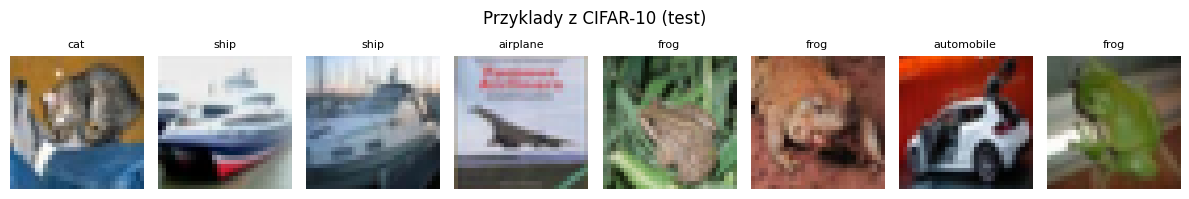

Ksztalt zbioru treningowego: (50000, 32, 32, 3) | Liczba klas: 10
Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Wyliczona srednia RGB (train): [0.4914, 0.4822, 0.4465]
Wyliczone odchylenie std RGB (train): [0.247, 0.2435, 0.2616]
Train batches: 391 | Test batches: 79

Model: 16 warstw z wagami | 1,110,442 parametrow
Test forward na rzeczywistym batchu: (128, 3, 32, 32) -> (128, 10)


In [3]:
DATA_DIR = Path("./data")


def compute_dataset_stats(data_dir: Path):
    """Wylicza srednia i odchylenie standardowe pikseli wprost ze zbioru treningowego."""
    raw_train_ds = datasets.CIFAR10(str(data_dir), train=True, download=True)
    pixels = raw_train_ds.data.astype(np.float64) / 255.0
    mean = tuple(pixels.mean(axis=(0, 1, 2)).tolist())
    std = tuple(pixels.std(axis=(0, 1, 2)).tolist())
    return mean, std, raw_train_ds.data.shape, raw_train_ds.classes


def make_loaders(data_dir: Path, batch_size: int, num_workers: int = 2):
    """Tworzy obiekty DataLoader dla zbioru treningowego i testowego CIFAR-10."""
    mean, std, train_shape, classes = compute_dataset_stats(data_dir)
    train_tf = transforms.Compose([
        transforms.RandomCrop(train_shape[1], padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    test_tf = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    train_ds = datasets.CIFAR10(str(data_dir), train=True, download=True, transform=train_tf)
    test_ds = datasets.CIFAR10(str(data_dir), train=False, download=True, transform=test_tf)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=DEVICE.type == "cuda")
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=DEVICE.type == "cuda")
    return train_loader, test_loader, classes, mean, std, train_shape

train_loader, test_loader, class_names, cifar_mean, cifar_std, train_shape = make_loaders(DATA_DIR, BATCH_SIZE)
in_channels = train_shape[-1]
num_classes = len(class_names)

print(f"Ksztalt zbioru treningowego: {train_shape} | Liczba klas: {num_classes}")
print(f"Klasy: {class_names}")
print(f"Wyliczona srednia RGB (train): {[round(m, 4) for m in cifar_mean]}")
print(f"Wyliczone odchylenie std RGB (train): {[round(s, 4) for s in cifar_std]}")
print(f"Train batches: {len(train_loader)} | Test batches: {len(test_loader)}")

model = HighwayCIFAR10(
    in_channels=in_channels,
    num_classes=num_classes,
    widths=STAGE_WIDTHS,
    blocks_per_stage=BLOCKS_PER_STAGE,
    transform_bias=TRANSFORM_BIAS,
)
xb, yb = next(iter(test_loader))
print(f"\nModel: {model.count_weighted_layers()} warstw z wagami | {model.count_parameters():,} parametrow")
print(f"Test forward na rzeczywistym batchu: {tuple(xb.shape)} -> {tuple(model(xb).shape)}")

# podglad kilku obrazow ze zbioru testowego (odwrocenie normalizacji)
inv_mean = torch.tensor(cifar_mean, dtype=xb.dtype).view(in_channels, 1, 1)
inv_std = torch.tensor(cifar_std, dtype=xb.dtype).view(in_channels, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    img = (xb[i] * inv_std + inv_mean).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(class_names[yb[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("Przyklady z CIFAR-10 (test)")
plt.tight_layout()
plt.show()

## 5. Trening i ewaluacja modelu

Proces uczenia i testowania sieci składa się z następujących elementów:

- **Funkcja straty (`nn.CrossEntropyLoss`):** Mierzymy błąd klasyfikacji za pomocą entropii krzyżowej, która zamienia 10 logitów wyjściowych sieci na rozkład prawdopodobieństwa i karze model tym mocniej, im niższe prawdopodobieństwo przypisał prawdziwej klasie obrazu.
- **Optymalizator (`torch.optim.SGD` z `momentum=0.9` i `weight_decay=1e-4`):** Trenujemy sieć bezpośrednio metodą stochastycznego spadku wzdłuż gradientu z pędem (`momentum=0.9` wygładza kierunek aktualizacji wag na podstawie poprzednich kroków, a `weight_decay=1e-4` dodaje regularyzację L2 ograniczającą przeuczenie).
- **Przycinanie gradientów (`clip_grad_norm_` z progiem `1.0`) oraz harmonogram `CosineAnnealingLR`:** Przycinanie normy gradientu chroni głęboką sieć przed pojedynczymi gwałtownymi skokami wag, natomiast harmonogram cosinusowy płynnie zmniejsza współczynnik uczenia `LR` od `0.05` do `0` w trakcie 100 epok, pozwalając precyzyjnie zbiec do minimum.
- **Tryb treningowy (`model.train()`) vs testowy (`model.eval()` i `@torch.no_grad()`):** Podczas treningu w każdej paczce zerujemy stare gradienty (`optimizer.zero_grad`), liczymy stratę, wywołujemy propagację wsteczną (`loss.backward()`) i aktualizujemy wagi (`optimizer.step()`). Podczas ewaluacji na zbiorze testowym wyłączamy śledzenie pochodnych (`@torch.no_grad()`) i przełączamy warstwy `BatchNorm2d` w tryb używania wyuczonych statystyk globalnych (`model.eval()`).

In [4]:
@torch.no_grad()
def evaluate(model, loader, device):
    """Oblicza srednia strate i dokladnosc klasyfikacji na zbiorze testowym."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        total_loss += criterion(logits, y).item()
        correct += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, 100.0 * correct / n


def train_one_epoch(model, loader, optimizer, device, grad_clip=1.0):
    """Przeprowadza jedna epoke treningu modelu i zwraca srednia strate oraz dokladnosc."""
    model.train()
    criterion = nn.CrossEntropyLoss()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in tqdm(loader, desc="train", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        if grad_clip > 0:
            nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, 100.0 * correct / n


RUNS_DIR = Path("./runs")

torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

model = HighwayCIFAR10(
    in_channels=in_channels,
    num_classes=num_classes,
    widths=STAGE_WIDTHS,
    blocks_per_stage=BLOCKS_PER_STAGE,
    transform_bias=TRANSFORM_BIAS,
).to(DEVICE)

if RETRAIN:
    run_dir = RUNS_DIR / f"run_{time.strftime('%Y%m%d_%H%M%S')}"
    run_dir.mkdir(parents=True, exist_ok=True)

    optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    history = []
    best_acc = 0.0
    print(f"Start treningu | params={model.count_parameters():,} | epochs={EPOCHS}")

    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, DEVICE)
        test_loss, test_acc = evaluate(model, test_loader, DEVICE)
        scheduler.step()
        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "test_loss": test_loss,
            "test_acc": test_acc,
            "lr": optimizer.param_groups[0]["lr"],
            "seconds": time.time() - t0,
        }
        history.append(row)
        print(
            f"Epoch {epoch:03d}/{EPOCHS} | "
            f"train {train_loss:.4f}/{train_acc:.2f}% | "
            f"test {test_loss:.4f}/{test_acc:.2f}% | "
            f"lr {row['lr']:.4g} | {row['seconds']:.1f}s"
        )
        if train_loss != train_loss:
            print("NaN — stop")
            break
        if test_acc > best_acc:
            best_acc = test_acc
            torch.save(
                {"model": model.state_dict(), "test_acc": test_acc, "epoch": epoch},
                run_dir / "best.pt",
            )
        with open(run_dir / "history.json", "w") as f:
            json.dump(history, f, indent=2)

    ckpt = torch.load(run_dir / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model"])
    print(f"Best test accuracy: {best_acc:.2f}% (epoch={ckpt.get('epoch')})")
    with open(run_dir / "summary.json", "w") as f:
        json.dump(
            {
                "best_test_acc": best_acc,
                "widths": list(STAGE_WIDTHS),
                "blocks_per_stage": list(BLOCKS_PER_STAGE),
                "params": model.count_parameters(),
            },
            f,
            indent=2,
        )
else:
    candidates = sorted(p for p in RUNS_DIR.glob("*/history.json") if (p.parent / "best.pt").is_file())
    if not candidates:
        raise FileNotFoundError(
            "Brak zapisanego przebiegu treningu. Ustaw RETRAIN = True i uruchom trening."
        )
    hist_path = candidates[-1]
    ckpt_path = hist_path.parent / "best.pt"
    with open(hist_path) as f:
        history = json.load(f)
    best_acc = max(r["test_acc"] for r in history)
    print(f"Wczytano historie: {hist_path}")
    print(f"Epoki: {len(history)} | najlepsze test acc: {best_acc:.2f}%")
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model"])
    print(f"Wczytano checkpoint: {ckpt_path} (epoch={ckpt.get('epoch')}, acc={ckpt.get('test_acc'):.2f}%)")

Start treningu | params=1,110,442 | epochs=100
Epoch 001/100 | train 1.5002/44.32% | test 1.3805/51.22% | lr 0.04999 | 5.6s
Epoch 002/100 | train 1.0221/63.29% | test 1.1539/61.49% | lr 0.04995 | 5.4s
Epoch 003/100 | train 0.8181/70.82% | test 1.0540/66.29% | lr 0.04989 | 5.5s
Epoch 004/100 | train 0.6921/75.74% | test 0.9848/69.42% | lr 0.0498 | 5.4s
Epoch 005/100 | train 0.6056/78.98% | test 0.8086/74.61% | lr 0.04969 | 5.5s
Epoch 006/100 | train 0.5460/81.15% | test 0.7920/74.53% | lr 0.04956 | 5.4s
Epoch 007/100 | train 0.4986/82.69% | test 0.9143/72.56% | lr 0.0494 | 5.5s
Epoch 008/100 | train 0.4526/84.32% | test 0.7320/78.40% | lr 0.04921 | 5.6s
Epoch 009/100 | train 0.4246/85.39% | test 0.7189/77.34% | lr 0.04901 | 5.4s
Epoch 010/100 | train 0.4015/86.18% | test 0.7330/77.23% | lr 0.04878 | 5.4s
Epoch 011/100 | train 0.3806/86.84% | test 0.7127/76.68% | lr 0.04852 | 5.5s
Epoch 012/100 | train 0.3546/87.76% | test 0.5996/80.94% | lr 0.04824 | 5.4s
Epoch 013/100 | train 0.3390/88

## 6. Wyniki i krzywe uczenia

Poniższa komórka wizualizuje przebieg funkcji kosztu (**Cross-entropy loss**) oraz dokładności klasyfikacji (**Accuracy [%]**) w kolejnych epokach dla zbioru treningowego i testowego, a także wykonuje bezpośrednią ewaluację wczytanego modelu na zbiorze testowym `test_loader`.

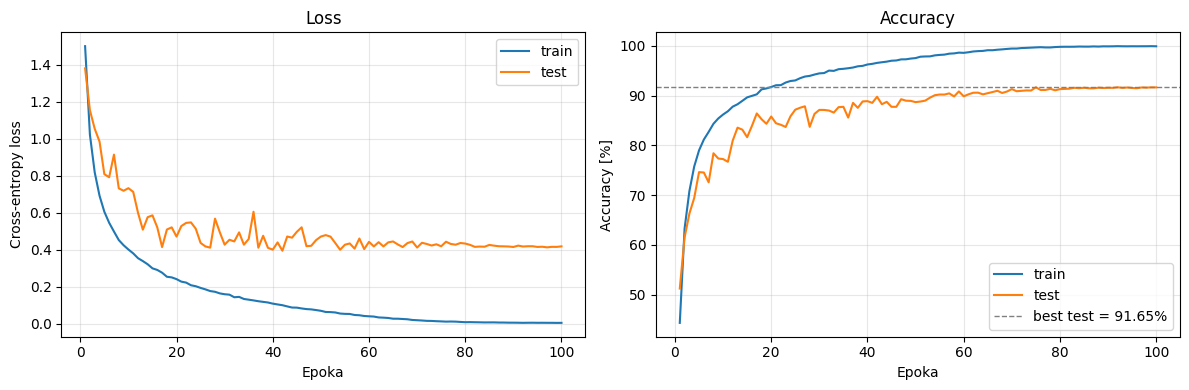

Architektura modelu:     widths=(32, 64, 96), blocks=(4, 4, 4) (16 warstw z wagami, 1,110,442 parametrow)
Najlepsze test accuracy: 91.65% (w historii treningu)
Ostatnie test accuracy:  91.63%
Test accuracy z modelu:  91.65% (loss = 0.4190)


In [5]:
epochs = [r["epoch"] for r in history]
train_acc = [r["train_acc"] for r in history]
test_acc = [r["test_acc"] for r in history]
train_loss = [r["train_loss"] for r in history]
test_loss = [r["test_loss"] for r in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, train_loss, label="train")
axes[0].plot(epochs, test_loss, label="test")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, train_acc, label="train")
axes[1].plot(epochs, test_acc, label="test")
axes[1].axhline(best_acc, color="gray", ls="--", lw=1, label=f"best test = {best_acc:.2f}%")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Accuracy [%]")
axes[1].set_title("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

eval_loss, eval_acc = evaluate(model, test_loader, DEVICE)
print(f"Architektura modelu:     widths={STAGE_WIDTHS}, blocks={BLOCKS_PER_STAGE} ({model.count_weighted_layers()} warstw z wagami, {model.count_parameters():,} parametrow)")
print(f"Najlepsze test accuracy: {best_acc:.2f}% (w historii treningu)")
print(f"Ostatnie test accuracy:  {test_acc[-1]:.2f}%")
print(f"Test accuracy z modelu:  {eval_acc:.2f}% (loss = {eval_loss:.4f})")